# Industry Project: A Production Feature-Engineering Pipeline for Return Prediction (Production-Style)

> **Who is this notebook for?** Beginners who know `fit` / `predict` and want to see how feature engineering is done **in a real company**: messy tables, several data sources, time, and the constant danger of data leakage.
> Every step is explained in plain English, and almost every line of code has a comment.

---

### How this notebook is different from `01_feature_engineering.ipynb`

| `01_feature_engineering.ipynb` | This notebook |
|---|---|
| Explains scaling, encoding, imputation, selection one by one | Combines them into **one production pipeline** |
| One clean table | **Three related tables** (orders, customers, products) that must be joined |
| Random train/test split | **Time-based** validation with a **label delay** |
| Shows that features help | **Measures how much each feature group helps** (ablation) |
| Mentions leakage | **Demonstrates two real leakage bugs** and how they fool you |

---

### The business problem

You work for an online fashion and lifestyle shop. About **1 in 5 orders is returned**. Each return costs the company around **$12** (shipping both ways, inspection, re-packing), and some returned items can no longer be sold at full price.

The product team wants a **return-risk score at checkout**, so they can e.g. show a size-advice pop-up or offer a "keep it" discount for high-risk orders.

Constraints that make this realistic:
- The score is computed **at the moment of checkout**. Only information available *at that time* may be used.
- Whether an order is returned is only known **up to 30 days later** (the return window). This is called **label delay**.
- New products and new customers appear every day.

**Success means:** a better ranking of risky orders (ROC-AUC / PR-AUC on *future* orders) using features that can really be computed in production.

---

### Table of Contents
1. Setup: imports and one central config
2. Get the data: three related tables
3. First look and data-quality problems
4. Cleaning function
5. Point-in-time features from the order history
6. Honest split: time-based, with a gap for the label delay
7. Custom feature transformers (datetime, ratios, text length)
8. The full `ColumnTransformer` with pandas output
9. Ablation study: what does each feature group add?
10. Leakage bug #1: a customer feature that knows the future
11. Leakage bug #2: target encoding without cross-fitting
12. Final out-of-time evaluation and business impact
13. Save the pipeline with its metadata
14. Serving: score one checkout using the "feature store"
15. Automated tests
16. Summary, exercises and resources

---
## 1. Setup: imports and one central config

In [1]:
# ---- Standard library ----
import json                      # save metadata as text
import logging                   # status messages with timestamps
import tempfile                  # temporary folder for saved artifacts (never write into the repo)
import time                      # measure runtimes
import warnings
from dataclasses import dataclass, asdict
from datetime import datetime, timezone
from pathlib import Path

# ---- Third-party ----
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, TargetEncoder
from threadpoolctl import threadpool_limits       # control CPU threads used by NumPy / OpenMP

warnings.filterwarnings("ignore")
logging.basicConfig(level=logging.INFO, format="%(asctime)s | %(levelname)s | %(message)s", force=True)
log = logging.getLogger("returns")

# Use ONE CPU thread for the numeric libraries. On a shared server (CI runner, notebook server, a laptop
# running other jobs) multi-threaded gradient boosting can become many times SLOWER because threads fight
# for the CPU. For datasets of this size one thread is fast enough; raise it on a dedicated machine.
threadpool_limits(limits=1)


@dataclass(frozen=True)
class Config:
    random_state: int = 42
    n_customers: int = 4_000
    n_products: int = 1_500
    n_orders: int = 30_000
    start_date: str = "2025-01-01"
    n_days: int = 546                    # ~18 months of orders
    return_window_days: int = 30         # a return is only KNOWN up to 30 days after the order
    test_days: int = 90                  # last 3 months = out-of-time test set
    cv_splits: int = 3                   # time-based cross-validation folds
    rare_min_frequency: float = 0.02     # categories below 2% of rows are grouped as "infrequent"
    cost_per_return_usd: float = 12.0    # shipping + handling for one return
    target: str = "returned"


CFG = Config()
log.info("scikit-learn %s, pandas %s", sklearn.__version__, pd.__version__)
print(CFG)

2026-10-21 17:58:59,174 | INFO | scikit-learn 1.9.0, pandas 2.3.3


Config(random_state=42, n_customers=4000, n_products=1500, n_orders=30000, start_date='2025-01-01', n_days=546, return_window_days=30, test_days=90, cv_splits=3, rare_min_frequency=0.02, cost_per_return_usd=12.0, target='returned')


---
## 2. Get the data: three related tables

Real feature engineering almost never starts from one tidy table. Here the data warehouse has three tables:

| Table | One row per | Example columns |
|---|---|---|
| `orders` | order (our prediction unit) | `order_ts`, `customer_id`, `product_id`, `price_paid`, `payment_method`, `customer_note`, `returned` |
| `customers` | customer | `signup_date`, `birth_year`, `country` |
| `products` | product | `category`, `brand`, `list_price` |

In a company you would load them with SQL (`pd.read_sql("SELECT ... FROM orders WHERE ...")`). Here we **simulate** them with a fixed seed. The simulator hides realistic drivers of returns (fashion is returned more, some products have bad sizing, some customers are "serial returners", deep discounts trigger impulse buys, ...) plus the usual mess: missing values, inconsistent spelling, rare categories. You can skim the code; the important part is what comes after.

In [2]:
def simulate_shop_tables(cfg: Config = CFG):
    """Create orders, customers and products tables that behave like a real web shop."""
    rng = np.random.default_rng(cfg.random_state)

    # ---------- products ----------
    categories = np.array(["apparel", "shoes", "electronics", "home", "beauty", "books"])
    base_price = {"apparel": 45, "shoes": 80, "electronics": 250, "home": 60, "beauty": 25, "books": 15}
    base_return = {"apparel": 1.0, "shoes": 0.8, "electronics": -0.2, "home": -0.5, "beauty": -1.0, "books": -1.5}
    prod_cat = rng.choice(categories, cfg.n_products, p=[.30, .15, .15, .15, .15, .10])
    brand_pool = [f"brand_{i:03d}" for i in range(300)]                      # 300 brands, long tail
    brand_weights = 1 / np.arange(1, 301) ** 1.1; brand_weights /= brand_weights.sum()
    # hidden "bad sizing" effect per product: strong for apparel/shoes, small for others
    fit_issue = rng.normal(0, 0.9, cfg.n_products) * np.isin(prod_cat, ["apparel", "shoes"]) + rng.normal(0, 0.3, cfg.n_products)
    products = pd.DataFrame({
        "product_id": [f"P{i:05d}" for i in range(cfg.n_products)],
        "category": prod_cat,
        "brand": rng.choice(brand_pool, cfg.n_products, p=brand_weights),
        "list_price": (np.array([base_price[c] for c in prod_cat]) * rng.lognormal(0, 0.5, cfg.n_products)).round(2),
    })

    # ---------- customers ----------
    returner_tendency = rng.normal(0, 1.0, cfg.n_customers)                 # hidden: serial returners
    country = rng.choice(["DE", "FR", "NL", "AT", "BE", "PL", "CH", "LU", "DK", "IS"], cfg.n_customers,
                         p=[.38, .2, .14, .1, .08, .05, .025, .01, .01, .005])
    customers = pd.DataFrame({
        "customer_id": [f"C{i:05d}" for i in range(cfg.n_customers)],
        "signup_date": pd.Timestamp("2023-01-01") + pd.to_timedelta(rng.integers(0, 900, cfg.n_customers), unit="D"),
        "birth_year": rng.integers(1950, 2007, cfg.n_customers).astype(float),
        "country": country,
    })
    customers.loc[rng.random(cfg.n_customers) < 0.25, "birth_year"] = np.nan    # many people skip this field

    # ---------- orders ----------
    activity = rng.gamma(1.5, 1, cfg.n_customers); activity /= activity.sum()     # some customers order a lot
    popularity = rng.pareto(1.2, cfg.n_products) + 1; popularity /= popularity.sum()
    c_idx = rng.choice(cfg.n_customers, cfg.n_orders, p=activity)
    p_idx = rng.choice(cfg.n_products, cfg.n_orders, p=popularity)
    order_ts = pd.Timestamp(cfg.start_date) + pd.to_timedelta(rng.uniform(0, cfg.n_days, cfg.n_orders), unit="D")
    discount = np.where(rng.random(cfg.n_orders) < 0.35, rng.choice([0.1, 0.2, 0.3, 0.5], cfg.n_orders), 0.0)
    price_paid = products["list_price"].to_numpy()[p_idx] * (1 - discount) * rng.uniform(0.97, 1.03, cfg.n_orders)
    payment = rng.choice(["card", "paypal", "klarna", "gift_card", "bank_transfer", "crypto"], cfg.n_orders,
                         p=[.45, .30, .17, .05, .02, .01])
    device = rng.choice(["mobile", "desktop", "app"], cfg.n_orders, p=[.5, .3, .2])
    cat = prod_cat[p_idx]
    size = np.where(np.isin(cat, ["apparel", "shoes"]), rng.choice(["S", "M", "L", "XL"], cfg.n_orders), None)
    size_missing = (rng.random(cfg.n_orders) < 0.15) & np.isin(cat, ["apparel", "shoes"])   # size guide skipped
    size = np.where(size_missing, None, size)
    is_gift = rng.random(cfg.n_orders) < 0.08
    notes_pool = ["", "", "", "", "please leave at the door", "ring twice", "deliver after 6pm",
                  "call me before delivery, the doorbell is broken and I work from home most days"]
    note = rng.choice(notes_pool, cfg.n_orders)
    note = np.where(is_gift, rng.choice(["this is a gift, please no invoice in the box",
                                         "gift for my sister", "Gift wrap please!"], cfg.n_orders), note)
    hour = order_ts.hour.to_numpy()
    guest = np.isnan(customers["birth_year"].to_numpy()[c_idx])            # missing birth year ~ guest-like checkout
    price_ratio = price_paid / np.array([base_price[c] for c in cat])

    # hidden "true" return behaviour
    logit = (-2.3 + np.array([base_return[c] for c in cat]) + fit_issue[p_idx] + returner_tendency[c_idx]
             + 0.5 * np.log(price_ratio) + 1.2 * discount + 0.4 * (payment == "klarna")
             + 0.35 * (hour < 5) + 0.3 * guest + 0.4 * is_gift + 0.5 * size_missing)
    returned = rng.binomial(1, 1 / (1 + np.exp(-logit)))

    # messy spelling, as it comes from different checkout front-ends
    payment = payment.astype(object)
    messy = rng.random(cfg.n_orders) < 0.06
    payment[messy] = [p.upper() + " " for p in payment[messy]]               # "PAYPAL " instead of "paypal"
    orders = pd.DataFrame({
        "order_id": [f"O{i:06d}" for i in range(cfg.n_orders)],
        "order_ts": order_ts, "customer_id": customers["customer_id"].to_numpy()[c_idx],
        "product_id": products["product_id"].to_numpy()[p_idx], "price_paid": price_paid.round(2),
        "discount_pct": discount, "payment_method": payment, "device": device, "size": size,
        "customer_note": np.where(rng.random(cfg.n_orders) < 0.1, None, note),   # NULL vs "" : both happen
        CFG.target: returned,
    }).sort_values("order_ts").reset_index(drop=True)
    return orders, customers, products


orders_raw, customers, products = simulate_shop_tables()
print(f"orders {orders_raw.shape}, customers {customers.shape}, products {products.shape}")
orders_raw.head()

orders (30000, 11), customers (4000, 4), products (1500, 4)


,order_id,order_ts,customer_id,product_id,price_paid,discount_pct,payment_method,device,size,customer_note,returned
0,O015751,2025-01-01 00:28:23.901653616,C00961,P01074,21.55,0.0,paypal,mobile,None,,0
1,O009610,2025-01-01 00:30:03.834675472,C02055,P01431,63.45,0.0,card,app,None,None,0
2,O011838,2025-01-01 00:31:30.620603078,C01600,P00340,38.77,0.0,card,mobile,XL,Gift wrap please!,1
3,O005628,2025-01-01 00:43:58.700357474,C02850,P00813,351.44,0.0,paypal,desktop,None,deliver after 6pm,1
4,O008805,2025-01-01 02:09:15.644653957,C00884,P00090,32.16,0.5,card,mobile,M,,0


---
## 3. First look and data-quality problems

The usual four questions: size, types, missing values, target balance. Plus one that matters a lot for feature engineering: **how many distinct values does each categorical column have?** (its *cardinality*).

In [3]:
print("Return rate:", f"{orders_raw[CFG.target].mean():.1%}")
print("\nMissing values (share of rows):")
print(pd.concat([orders_raw.isna().mean(), customers.isna().mean()]).loc[lambda s: s > 0].round(3))

print("\nCardinality (number of distinct values):")
print({"product_id": orders_raw["product_id"].nunique(), "brand": products["brand"].nunique(),
       "customer_id": orders_raw["customer_id"].nunique(), "payment_method": orders_raw["payment_method"].nunique(),
       "country": customers["country"].nunique()})

print("\npayment_method values (note the messy spelling):")
print(orders_raw["payment_method"].value_counts().head(12))

Return rate: 18.9%

Missing values (share of rows):
size             0.664
customer_note    0.102
birth_year       0.245
dtype: float64

Cardinality (number of distinct values):
{'product_id': 1496, 'brand': 215, 'customer_id': 3740, 'payment_method': 12, 'country': 10}

payment_method values (note the messy spelling):
payment_method
card              12629
paypal             8498
klarna             4881
gift_card          1369
CARD                788
bank_transfer       569
PAYPAL              542
KLARNA              300
crypto              284
GIFT_CARD            90
BANK_TRANSFER        39
CRYPTO               11
Name: count, dtype: int64


**What we learned:**
- ~20% of orders are returned: imbalanced, so we use **ROC-AUC** and **PR-AUC** instead of accuracy.
- `product_id` (1,500 values) and `brand` (~200 distinct values, long tail) are **high-cardinality** categoricals: one-hot encoding them would create thousands of sparse columns, and most products have too few orders to learn from. We will use **target encoding**.
- `payment_method` and `country` have **rare** values (`crypto`, `IS`, ...) and messy spelling (`"PAYPAL "`). We will clean them and **group rare categories**.
- `birth_year`, `size` and `customer_note` have missing values, and **the fact that a value is missing may itself be informative** (a skipped size guide!). We will add **missing-value indicators**.

---
## 4. Cleaning function

Cleaning is a **function** so it runs identically in training, in the nightly batch job and in the checkout API.

In [4]:
def clean_orders(df: pd.DataFrame) -> pd.DataFrame:
    """Fix known data-quality issues. Returns a NEW DataFrame."""
    df = df.copy()
    df["payment_method"] = df["payment_method"].str.strip().str.lower()       # "PAYPAL " -> "paypal"
    df["customer_note"] = df["customer_note"].fillna("")                      # NULL and "" mean the same here
    df["order_ts"] = pd.to_datetime(df["order_ts"])
    df = df.drop_duplicates(subset="order_id")
    return df.sort_values("order_ts").reset_index(drop=True)                  # time order matters below


orders = clean_orders(orders_raw)
print(orders["payment_method"].value_counts())

payment_method
card             13417
paypal            9040
klarna            5181
gift_card         1459
bank_transfer      608
crypto             295
Name: count, dtype: int64


---
## 5. Point-in-time features from the order history

Some of the most predictive features come from a **related table**: what did this customer do *before*?

- `cust_prev_orders`: number of earlier orders
- `cust_days_since_prev_order`: days since their previous order
- `cust_avg_prev_spend`: average price of earlier orders
- `cust_known_returns` / `cust_return_rate`: how often they returned in the past

**The trap:** the label delay. At checkout time, the orders from the **last 30 days** have no known outcome yet (the customer may still return them). So `cust_return_rate` may only use orders whose return window **closed before** this checkout. A feature computed with information that did not exist yet is called **point-in-time incorrect**, and it is one of the most common leakage bugs in industry. Feature stores (Feast, Tecton, Databricks) exist largely to get this right; see `../../15_MLOps/12_feature_stores.ipynb`.

How the code works (vectorised, no slow Python loop): every past order creates an **"outcome known" event** at `order_ts + 30 days`. We merge these events with the checkouts in time order and count, per customer, the events that happened before each checkout.

We also **smooth** the return rate: a customer with 1 return out of 1 order is not a "100% returner". We blend their history with the overall rate, weighted by how much history they have: `(returns + prior × k) / (known_orders + k)`.

In [5]:
def add_customer_history_features(orders: pd.DataFrame, window_days: int = CFG.return_window_days,
                                  prior_rate: float = 0.20, prior_strength: float = 5.0) -> pd.DataFrame:
    """Add point-in-time customer features. Each row only sees information available at its order_ts."""
    df = orders.sort_values("order_ts").reset_index(drop=True).copy()
    g = df.groupby("customer_id")

    # 1. Simple history: previous orders are known immediately at checkout
    df["cust_prev_orders"] = g.cumcount()                                         # 0 for a first order
    prev_ts = g["order_ts"].shift(1)                                              # the previous order's time
    df["cust_days_since_prev_order"] = (df["order_ts"] - prev_ts).dt.total_seconds() / 86400
    df["cust_avg_prev_spend"] = g["price_paid"].transform(lambda s: s.shift(1).expanding().mean())

    # 2. Returns: an order's outcome only becomes KNOWN window_days after the order
    events = pd.DataFrame({"customer_id": df["customer_id"],
                           "t": df["order_ts"] + pd.Timedelta(days=window_days),   # when the outcome is known
                           "is_event": 1, "event_return": df[CFG.target], "row": -1})
    queries = pd.DataFrame({"customer_id": df["customer_id"], "t": df["order_ts"],
                            "is_event": 0, "event_return": 0, "row": np.arange(len(df))})
    timeline = (pd.concat([events, queries])
                .sort_values(["customer_id", "t", "is_event"], ascending=[True, True, False]))   # events first on ties
    timeline["known_orders"] = timeline.groupby("customer_id")["is_event"].cumsum()
    timeline["known_returns"] = timeline.groupby("customer_id")["event_return"].cumsum()
    at_checkout = timeline[timeline["is_event"] == 0].set_index("row").sort_index()

    df["cust_known_orders"] = at_checkout["known_orders"].to_numpy()
    df["cust_known_returns"] = at_checkout["known_returns"].to_numpy()
    df["cust_return_rate"] = ((df["cust_known_returns"] + prior_rate * prior_strength)
                              / (df["cust_known_orders"] + prior_strength))     # smoothed rate
    return df


def build_feature_table(orders, customers, products) -> pd.DataFrame:
    """The 'offline feature store join': one wide row per order with only point-in-time-correct columns."""
    df = add_customer_history_features(orders)
    df = df.merge(customers, on="customer_id", how="left", validate="many_to_one")   # validate catches bad joins
    df = df.merge(products, on="product_id", how="left", validate="many_to_one")
    return df


t0 = time.perf_counter()
data = build_feature_table(orders, customers, products)
log.info("Feature table built in %.1fs: %s", time.perf_counter() - t0, data.shape)
data[["order_ts", "customer_id", "cust_prev_orders", "cust_known_orders", "cust_known_returns",
      "cust_return_rate", CFG.target]].query("customer_id == 'C00010'").head(8)

2026-10-21 17:59:04,584 | INFO | Feature table built in 4.6s: (30000, 23)


,order_ts,customer_id,cust_prev_orders,cust_known_orders,cust_known_returns,cust_return_rate,returned
2670,2025-02-18 15:32:24.136884072,C00010,0,0,0,0.200000,1
4880,2025-03-31 01:28:05.918498529,C00010,1,1,1,0.333333,0
6394,2025-04-27 14:07:06.204743195,C00010,2,1,1,0.333333,0
7622,2025-05-19 22:58:45.270282918,C00010,3,2,1,0.285714,0
8649,2025-06-08 06:27:36.147375835,C00010,4,3,1,0.250000,0
12121,2025-08-09 07:05:56.269284682,C00010,5,5,1,0.200000,0
13045,2025-08-26 18:38:14.173017319,C00010,6,5,1,0.200000,1
16812,2025-11-03 03:43:26.415094480,C00010,7,7,2,0.250000,1


Look at one customer's rows above: `cust_known_orders` lags behind `cust_prev_orders` because the most recent orders are still inside the 30-day return window. That lag is exactly what production will see.

`validate="many_to_one"` in `merge` is a cheap insurance policy: if the `products` table accidentally had duplicate IDs, the join would silently duplicate orders. With `validate`, pandas raises an error instead.

---
## 6. Honest split: time-based, with a gap for the label delay

The model will score **future** checkouts, so we test on the **last 90 days** (out-of-time test) and train on everything before.

There is one more subtlety: the training orders from the **last 30 days before the cut-off** would not have known labels yet at training time. A real training job run on the cut-off date could not use them. We drop them (a "gap") to mimic reality. The same gap is used inside time-based cross-validation (`TimeSeriesSplit(gap=...)`).

In [6]:
from sklearn.model_selection import TimeSeriesSplit

test_start = data["order_ts"].max() - pd.Timedelta(days=CFG.test_days)
label_known_until = test_start - pd.Timedelta(days=CFG.return_window_days)

train = data[data["order_ts"] < label_known_until].reset_index(drop=True)    # labels known at training time
test = data[data["order_ts"] >= test_start].reset_index(drop=True)            # the future
y_train, y_test = train[CFG.target], test[CFG.target]

print(f"Train: {train['order_ts'].min():%Y-%m-%d} -> {train['order_ts'].max():%Y-%m-%d}  ({len(train):,} orders)")
print(f"Gap  : {label_known_until:%Y-%m-%d} -> {test_start:%Y-%m-%d}  (labels not yet known at training time)")
print(f"Test : {test['order_ts'].min():%Y-%m-%d} -> {test['order_ts'].max():%Y-%m-%d}  ({len(test):,} orders)")
print(f"New products in test never seen in train: {(~test['product_id'].isin(train['product_id'])).mean():.1%} of test orders")

orders_per_day = len(train) / (train["order_ts"].max() - train["order_ts"].min()).days
time_cv = TimeSeriesSplit(n_splits=CFG.cv_splits, gap=int(orders_per_day * CFG.return_window_days))
print(f"Time-based CV: {CFG.cv_splits} folds, gap of {time_cv.gap:,} orders (~{CFG.return_window_days} days)")

Train: 2025-01-01 -> 2026-03-02  (23,326 orders)
Gap  : 2026-03-02 -> 2026-04-01  (labels not yet known at training time)
Test : 2026-04-01 -> 2026-06-30  (4,997 orders)
New products in test never seen in train: 0.2% of test orders
Time-based CV: 3 folds, gap of 1,646 orders (~30 days)


---
## 7. Custom feature transformers (datetime, ratios, text length)

Anything that **learns from data** (a median, a category average) must happen **inside the pipeline**, so it is learned from the training fold only. We write small scikit-learn transformers. Each has:
- `fit(X, y)`: learn what is needed (or nothing),
- `transform(X)`: create the new columns,
- `get_feature_names_out()`: tell scikit-learn the new column names (needed for pandas output).

**7a. Datetime features.** Models cannot use a raw timestamp. We extract the hour, day of week, weekend flag, a "night-owl" flag and the customer's account age at order time.

In [7]:
class DateTimeFeatures(BaseEstimator, TransformerMixin):
    """order_ts + signup_date -> hour, weekday, weekend, night flag, account age (days)."""
    def fit(self, X, y=None):
        return self                                                   # fixed formulas: nothing to learn

    def transform(self, X):
        ts = pd.to_datetime(X["order_ts"])
        out = pd.DataFrame(index=X.index)
        out["order_hour"] = ts.dt.hour
        out["order_weekday"] = ts.dt.dayofweek                        # 0 = Monday
        out["is_weekend"] = (ts.dt.dayofweek >= 5).astype(int)
        out["is_night"] = (ts.dt.hour < 5).astype(int)               # impulse shopping at 2am?
        out["account_age_days"] = (ts - pd.to_datetime(X["signup_date"])).dt.days
        return out

    def get_feature_names_out(self, input_features=None):
        return np.array(["order_hour", "order_weekday", "is_weekend", "is_night", "account_age_days"])


class PriceRatioFeatures(BaseEstimator, TransformerMixin):
    """Price relative to the typical price of its category (the median is LEARNED in fit)."""
    def fit(self, X, y=None):
        self.category_median_ = X.groupby("category")["price_paid"].median()   # from training rows only
        self.global_median_ = float(X["price_paid"].median())                   # fallback for new categories
        return self

    def transform(self, X):
        median = X["category"].map(self.category_median_).fillna(self.global_median_)
        out = pd.DataFrame(index=X.index)
        out["price_vs_category_median"] = X["price_paid"] / median            # 2.0 = twice the usual price
        out["discount_amount"] = X["price_paid"] / (1 - X["discount_pct"]) * X["discount_pct"]
        return out

    def get_feature_names_out(self, input_features=None):
        return np.array(["price_vs_category_median", "discount_amount"])


class TextStatsFeatures(BaseEstimator, TransformerMixin):
    """Cheap, robust text features from the free-text customer note."""
    keywords = ("gift",)                                               # words the business says matter

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        note = X["customer_note"].fillna("").str.lower()
        out = pd.DataFrame(index=X.index)
        out["note_n_chars"] = note.str.len()
        out["note_n_words"] = note.str.split().str.len().fillna(0)
        out["note_is_empty"] = (note.str.len() == 0).astype(int)
        for word in self.keywords:
            out[f"note_mentions_{word}"] = note.str.contains(word, regex=False).astype(int)
        return out

    def get_feature_names_out(self, input_features=None):
        return np.array(["note_n_chars", "note_n_words", "note_is_empty"] + [f"note_mentions_{w}" for w in self.keywords])


# Quick look at what each transformer produces on 3 training rows
sample = train.head(3)
pd.concat([DateTimeFeatures().fit_transform(sample), PriceRatioFeatures().fit(train).transform(sample),
           TextStatsFeatures().fit_transform(sample)], axis=1)

,order_hour,order_weekday,is_weekend,is_night,account_age_days,price_vs_category_median,discount_amount,note_n_chars,note_n_words,note_is_empty,note_mentions_gift
0,0,2,0,1,662,0.983569,0.0,0,0,1,0
1,0,2,0,1,165,1.174565,0.0,0,0,1,0
2,0,2,0,1,44,1.003494,0.0,17,3,0,1


---
## 8. The full `ColumnTransformer` with pandas output

We group the features into **named blocks**, so we can switch each block on and off for the ablation study:

| Block | Columns in | Steps | Why |
|---|---|---|---|
| `base_num` | price, discount | median imputation | raw numbers |
| `base_cat` | category, payment, device, country, size | `OneHotEncoder(min_frequency=0.02, handle_unknown="infrequent_if_exist")` | rare values (`crypto`, `IS`) are **grouped** into one "infrequent" column; unseen values don't crash |
| `datetime` | order_ts, signup_date | `DateTimeFeatures` | time patterns |
| `missing_flags` | birth_year, size | `SimpleImputer(add_indicator=True)` | "value is missing" as its own feature |
| `ratios` | price, category, discount | `PriceRatioFeatures` | prices only make sense relative to the category |
| `history` | cust_* columns | imputation | point-in-time customer behaviour |
| `target_enc` | product_id, brand | `TargetEncoder` (with internal **cross-fitting**) | high-cardinality IDs -> one number each |
| `text` | customer_note | `TextStatsFeatures` | note length, gift keyword |

`set_output(transform="pandas")` makes the pipeline return a **DataFrame with readable column names** instead of an anonymous NumPy array. This is a huge help when debugging ("why is column 37 weird?").

> **Why TargetEncoder?** It replaces each product by "the average return rate of that product", shrunk towards the global rate when the product has few orders. The danger is that a row's **own label** leaks into its encoding. scikit-learn's `TargetEncoder.fit_transform` therefore uses **cross-fitting**: the training rows are split into 5 folds and each fold is encoded with statistics from the *other* folds. Inside a Pipeline this happens automatically. Section 11 shows what happens without it.

In [8]:
FEATURE_BLOCKS = {
    "base_num": (SimpleImputer(strategy="median"), ["price_paid", "discount_pct"]),
    "base_cat": (Pipeline([("fill", SimpleImputer(strategy="constant", fill_value="unknown")),
                           ("onehot", OneHotEncoder(min_frequency=CFG.rare_min_frequency,
                                                    handle_unknown="infrequent_if_exist", sparse_output=False))]),
                 ["category", "payment_method", "device", "country", "size"]),
    "datetime": (DateTimeFeatures(), ["order_ts", "signup_date"]),
    "missing_flags": (SimpleImputer(strategy="median", add_indicator=True), ["birth_year"]),
    "ratios": (PriceRatioFeatures(), ["price_paid", "category", "discount_pct"]),
    "history": (SimpleImputer(strategy="median"), ["cust_prev_orders", "cust_days_since_prev_order",
                                                   "cust_avg_prev_spend", "cust_known_orders", "cust_return_rate"]),
    # cross-fitting folds: shuffled with a fixed seed so results are reproducible (scikit-learn >= 1.9 API)
    "target_enc": (TargetEncoder(target_type="binary",
                                 cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=CFG.random_state)),
                   ["product_id", "brand"]),
    "text": (TextStatsFeatures(), ["customer_note"]),
}


def make_feature_pipeline(blocks, model=None) -> Pipeline:
    """Build features (only the chosen blocks) + model, as ONE pipeline object."""
    transformers = [(name, clone(FEATURE_BLOCKS[name][0]), FEATURE_BLOCKS[name][1]) for name in blocks]
    features = ColumnTransformer(transformers, remainder="drop", verbose_feature_names_out=True)
    model = model if model is not None else HistGradientBoostingClassifier(
        learning_rate=0.1, max_iter=150, max_leaf_nodes=31, min_samples_leaf=40, random_state=CFG.random_state)
    pipe = Pipeline([("features", features), ("model", clone(model))])
    return pipe.set_output(transform="pandas")              # every step outputs a DataFrame


ALL_BLOCKS = list(FEATURE_BLOCKS)
full_features = make_feature_pipeline(ALL_BLOCKS)[:-1]      # just the feature part, without the model
X_preview = full_features.fit_transform(train, y_train)     # y is needed by TargetEncoder
print(f"{X_preview.shape[1]} model features. A few of them:")
X_preview.iloc[:3, ::3]

50 model features. A few of them:


,base_num__price_paid,base_cat__category_beauty,base_cat__category_home,base_cat__payment_method_card,base_cat__payment_method_paypal,base_cat__device_desktop,base_cat__country_BE,base_cat__country_FR,base_cat__country_infrequent_sklearn,base_cat__size_S,datetime__order_hour,datetime__is_night,missing_flags__missingindicator_birth_year,history__cust_prev_orders,history__cust_known_orders,target_enc__brand,text__note_is_empty
0,21.55,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0,1,0.0,0.0,0.0,0.249662,1
1,63.45,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0,1,0.0,0.0,0.0,0.126186,1
2,38.77,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0,1,0.0,0.0,0.0,0.126186,0


Every column name says which block made it (`target_enc__brand`, `history__cust_known_orders`, `missing_flags__missingindicator_birth_year`, ...). Notice `base_cat__country_infrequent_sklearn`: that single column holds all the rare countries (`LU`, `DK`, `IS`, ...) that were grouped together.

> In the table above, `size` is missing for most non-fashion orders (they have no size), and for some fashion orders (the customer skipped the size guide). The one-hot block turns missing into the category `"unknown"`, so "missing" becomes a feature by itself.

---
## 9. Ablation study: what does each feature group add?

Engineers love adding features. The honest question is: **does each group actually help on future data?** An **ablation study** answers it:

1. Start with the base features.
2. Add one block at a time and measure time-based CV ROC-AUC and PR-AUC.
3. Keep blocks that add clearly more than the noise (the ± std across folds).

Each extra block costs something in production (another data source, more code, more monitoring), so a block that adds nothing should be **removed**.

2026-10-21 17:59:52,003 | INFO | Ablation done in 46s


     added_block  roc_auc  roc_auc_std  pr_auc  gain_roc_auc
base (num + cat)   0.7114       0.0168  0.3411        0.0000
        datetime   0.7052       0.0212  0.3298       -0.0062
   missing_flags   0.7097       0.0201  0.3361        0.0045
          ratios   0.7092       0.0211  0.3385       -0.0005
         history   0.7229       0.0255  0.3594        0.0137
      target_enc   0.7385       0.0300  0.4075        0.0156
            text   0.7398       0.0274  0.4093        0.0013


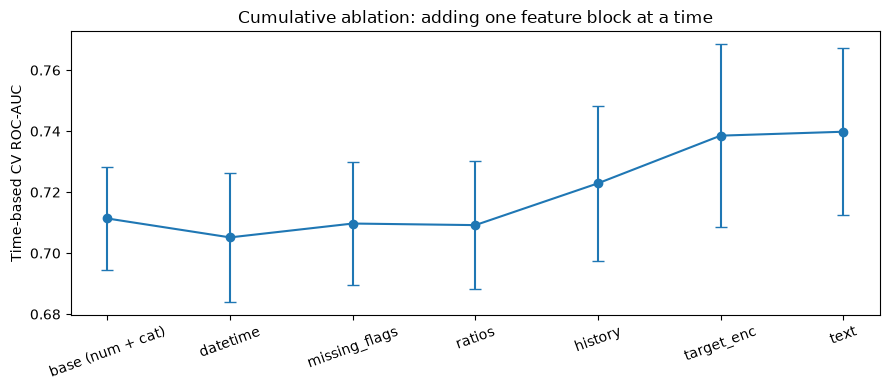

In [9]:
from sklearn.model_selection import cross_validate


def time_cv_scores(blocks, data_=train, y_=y_train) -> dict:
    """Time-based CV scores for a pipeline with the given feature blocks."""
    scores = cross_validate(make_feature_pipeline(blocks), data_, y_, cv=time_cv,
                            scoring={"roc_auc": "roc_auc", "pr_auc": "average_precision"}, n_jobs=1)
    return {"roc_auc": scores["test_roc_auc"].mean(), "roc_auc_std": scores["test_roc_auc"].std(),
            "pr_auc": scores["test_pr_auc"].mean()}


ablation_order = ["base_num", "base_cat", "datetime", "missing_flags", "ratios", "history", "target_enc", "text"]
rows, blocks = [], []
t0 = time.perf_counter()
for block in ablation_order:
    blocks = blocks + [block]
    if block == "base_num":
        continue                                            # evaluate base_num + base_cat together as "base"
    rows.append({"added_block": block if len(blocks) > 2 else "base (num + cat)", **time_cv_scores(blocks)})
log.info("Ablation done in %.0fs", time.perf_counter() - t0)

ablation = pd.DataFrame(rows)
ablation["gain_roc_auc"] = ablation["roc_auc"].diff().fillna(0)
print(ablation.round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 4))
ax.errorbar(ablation["added_block"], ablation["roc_auc"], yerr=ablation["roc_auc_std"], marker="o", capsize=4)
ax.set_ylabel("Time-based CV ROC-AUC"); ax.set_title("Cumulative ablation: adding one feature block at a time")
plt.xticks(rotation=20); plt.tight_layout(); plt.show()

**How to read the ablation (compare each gain with the ± std):**
- The **history** block (point-in-time customer behaviour) and **target encoding** of product/brand are the only clear winners (gains of roughly +0.01 to +0.02 ROC-AUC each). That matches the hidden truth of the simulator: serial returners and badly-sized products drive returns. In real return-prediction projects, these two are also usually the top features.
- **Datetime**, **missing flags**, **ratios** and **text** change the CV score by only a few thousandths, up or down: **less than the fold-to-fold noise**. The simulator *does* contain small effects for night orders, missing birth year and gift notes, but they are too weak to show up reliably in a 3-fold CV, and the trees can partly recover price effects from the raw `price_paid` + `category` columns. Honest conclusion: these blocks are "maybe" features.
- A cumulative ablation depends on the **order** in which blocks are added (correlated blocks "steal" credit from each other). The drop-one check below complements it.

### Drop-one check on the out-of-time test set
Train the full pipeline with **one block removed** and see how much the future-test ROC-AUC drops.

In [10]:
t0 = time.perf_counter()
full_pipe = make_feature_pipeline(ALL_BLOCKS).fit(train, y_train)
full_auc = roc_auc_score(y_test, full_pipe.predict_proba(test)[:, 1])
drop_rows = []
for block in ["datetime", "missing_flags", "ratios", "history", "target_enc", "text"]:
    reduced = make_feature_pipeline([b for b in ALL_BLOCKS if b != block]).fit(train, y_train)
    auc = roc_auc_score(y_test, reduced.predict_proba(test)[:, 1])
    drop_rows.append({"dropped_block": block, "test_roc_auc": round(auc, 4), "loss_vs_full": round(full_auc - auc, 4)})
log.info("Drop-one done in %.0fs", time.perf_counter() - t0)
print(f"Full pipeline, out-of-time test ROC-AUC: {full_auc:.4f}")
pd.DataFrame(drop_rows).sort_values("loss_vs_full", ascending=False)

2026-10-21 18:00:04,824 | INFO | Drop-one done in 12s


Full pipeline, out-of-time test ROC-AUC: 0.7759


,dropped_block,test_roc_auc,loss_vs_full
3,history,0.7463,0.0295
4,target_enc,0.7604,0.0154
0,datetime,0.7770,-0.0011
1,missing_flags,0.7781,-0.0022
5,text,0.7790,-0.0031
2,ratios,0.7801,-0.0042


The drop-one view tells the same story: removing **history** (≈ -0.03 AUC) or **target encoding** (≈ -0.015) hurts by far the most. Removing any of the four small blocks does **not** hurt at all on the test period: the test AUC even moves up by 0.001-0.004, which is within noise on ~5,000 test orders. So the honest conclusion is that, for this model and this data, datetime, missing-flag, ratio and text features add nothing measurable. The decision for such blocks is a **cost/benefit call**: a cheap, stable feature (like the hour of the order) may stay if the business believes in it; a block that needs a new data source or complex code should be removed until it proves itself. Simpler pipelines break less often.

---
## 10. Leakage bug #1: a customer feature that knows the future

A very common mistake: an analyst computes "customer return rate" with a simple `groupby` over the **whole** orders table:

```python
data["cust_return_rate_leaky"] = data.groupby("customer_id")["returned"].transform("mean")
```

This uses **future orders and the row's own label**. Let's see how good it *looks*, and then what happens in production, where only the point-in-time value is available at checkout.

In [11]:
leaky_train = train.copy()
leaky_train["cust_return_rate"] = train.groupby("customer_id")[CFG.target].transform("mean")   # THE BUG

leaky_pipe = make_feature_pipeline(ALL_BLOCKS)
leaky_cv = cross_validate(leaky_pipe, leaky_train, y_train, cv=time_cv, scoring="roc_auc")["test_score"].mean()
leaky_pipe.fit(leaky_train, y_train)

# In production the checkout API can only compute the point-in-time value -> that's what the model receives
prod_auc_leaky_model = roc_auc_score(y_test, leaky_pipe.predict_proba(test)[:, 1])

honest_cv = ablation["roc_auc"].iloc[-1]
print(f"{'':32s}{'CV ROC-AUC':>12s}{'production ROC-AUC':>20s}")
print(f"{'Leaky feature (groupby mean)':32s}{leaky_cv:12.4f}{prod_auc_leaky_model:20.4f}")
print(f"{'Point-in-time feature':32s}{honest_cv:12.4f}{full_auc:20.4f}")

                                  CV ROC-AUC  production ROC-AUC
Leaky feature (groupby mean)          0.8700              0.7769
Point-in-time feature                 0.7398              0.7759


This is the classic leakage story:
- In **cross-validation**, the leaky model looks **much better** than the honest one (by more than 0.1 ROC-AUC). A team would celebrate and ship it.
- In **production**, the feature must be computed honestly, and the "huge improvement" **disappears completely**: the leaky model scores about the same as the honest model (the difference is a few thousandths, i.e. noise). Worse still, the team would have promised the business a quality level that never materialises, and planned budgets around it.

**Red flags that should make you suspicious:** a single feature that dominates everything, a big jump in CV score from one "simple" feature, or CV scores much higher than what the business expected.

---
## 11. Leakage bug #2: target encoding without cross-fitting

Now a subtler bug. Suppose we encode `product_id` by hand with a plain `groupby` mean on the training set (no cross-fitting). For products with only a few orders, the encoding is basically **the row's own label**. The model learns "this encoded value = the answer" and overfits.

We compare:
- **Naive**: product/brand mean return rate computed on all training rows, then used as a feature.
- **Cross-fitted**: scikit-learn's `TargetEncoder` inside the pipeline (what we used above).

In [12]:
class NaiveMeanEncoder(BaseEstimator, TransformerMixin):
    """WRONG ON PURPOSE: category -> mean target, computed on the same rows it is applied to."""
    def fit(self, X, y):
        self.columns_ = list(X.columns)
        frame = X.assign(_y=np.asarray(y))
        self.maps_ = {c: frame.groupby(c)["_y"].mean() for c in self.columns_}
        self.global_ = float(np.mean(y))
        return self

    def transform(self, X):
        return pd.DataFrame({c: X[c].map(self.maps_[c]).fillna(self.global_) for c in self.columns_}, index=X.index)

    def get_feature_names_out(self, input_features=None):
        return np.array(self.columns_)


def train_and_score(pipe):
    pipe.fit(train, y_train)
    return (roc_auc_score(y_train, pipe.predict_proba(train)[:, 1]),
            roc_auc_score(y_test, pipe.predict_proba(test)[:, 1]))


naive_pipe = make_feature_pipeline(ALL_BLOCKS)
naive_pipe.steps[0][1].transformers = [(n, NaiveMeanEncoder() if n == "target_enc" else t, c)
                                       for n, t, c in naive_pipe.steps[0][1].transformers]
naive_train_auc, naive_test_auc = train_and_score(naive_pipe)
cf_train_auc, cf_test_auc = train_and_score(make_feature_pipeline(ALL_BLOCKS))

print(f"{'':28s}{'train ROC-AUC':>14s}{'test ROC-AUC':>14s}")
print(f"{'Naive mean encoding':28s}{naive_train_auc:14.4f}{naive_test_auc:14.4f}")
print(f"{'TargetEncoder (cross-fit)':28s}{cf_train_auc:14.4f}{cf_test_auc:14.4f}")

                             train ROC-AUC  test ROC-AUC
Naive mean encoding                 0.8615        0.7431
TargetEncoder (cross-fit)           0.8432        0.7759


The naive encoder makes the model look **excellent on the training data** (it can partly read the answer from the encoding) and do **worse on future orders** than the cross-fitted `TargetEncoder`. A large gap between train and test score is the typical symptom of target leakage.

The rule: **any feature computed from the target must be computed out-of-fold** (cross-fitting) for training rows. `TargetEncoder` does this for you in `fit_transform`, and at prediction time (`transform`) it uses the encoding learned from all training rows.

---
## 12. Final out-of-time evaluation and business impact

We already trained `full_pipe` on the training period. Let's translate its ranking into money. Suppose the product team can show a "check your size" intervention to the **riskiest 10%** of checkouts, that this prevents 25% of the returns it touches, and that the real shop has about **1 million orders per year** (our data is a sample).

In [13]:
test_proba = full_pipe.predict_proba(test)[:, 1]
base_pipe = make_feature_pipeline(["base_num", "base_cat"]).fit(train, y_train)
base_proba = base_pipe.predict_proba(test)[:, 1]


ORDERS_PER_YEAR = 1_000_000          # the real shop is much bigger than our sample


def returns_prevented(proba, y, share=0.10, prevent_rate=0.25):
    """How many returns would an intervention on the top `share` riskiest orders prevent?"""
    top = np.argsort(-proba)[: int(len(proba) * share)]          # riskiest orders first
    caught = y.to_numpy()[top].sum()                            # returns among targeted orders
    return caught, caught * prevent_rate


rows = []
for name, proba in [("base features only", base_proba), ("full feature pipeline", test_proba)]:
    caught, prevented = returns_prevented(proba, y_test)
    rows.append({"model": name, "test_roc_auc": round(roc_auc_score(y_test, proba), 4),
                 "test_pr_auc": round(average_precision_score(y_test, proba), 4),
                 "returns_in_top_10pct": int(caught),
                 "precision_top_10pct": round(caught / int(len(proba) * 0.10), 3),
                 "savings_per_year_usd": round(prevented / len(proba) * ORDERS_PER_YEAR * CFG.cost_per_return_usd, -2)})
impact = pd.DataFrame(rows)
print(f"Test period: {len(test):,} orders, {y_test.sum():,} returns ({y_test.mean():.1%})")
impact

Test period: 4,997 orders, 951 returns (19.0%)


,model,test_roc_auc,test_pr_auc,returns_in_top_10pct,precision_top_10pct,savings_per_year_usd
0,base features only,0.7306,0.3688,209,0.419,125500.0
1,full feature pipeline,0.7759,0.4666,282,0.565,169300.0


Feature engineering, not a different algorithm, is what moved the needle here: the **same** gradient-boosting model with better features finds many more of the returns in its top 10% (higher precision), and, scaled to a shop with one million orders per year, the estimated savings grow by tens of thousands of dollars per year. That is the number to put in front of the product team.

---
## 13. Save the pipeline with its metadata

We save the **whole pipeline** (feature blocks + model) as one file. The metadata lists the **input columns** the checkout service must send, and which of them come from the feature store (point-in-time history).

We save into a temporary folder so this tutorial doesn't add files to the repository. In a real project this would be `models/return_risk/v1/`.

In [14]:
ARTIFACT_DIR = Path(tempfile.mkdtemp(prefix="return_risk_"))          # real life: models/return_risk/v1/
joblib.dump(full_pipe, ARTIFACT_DIR / "pipeline.joblib")

input_columns = sorted({c for _, (_, cols) in FEATURE_BLOCKS.items() for c in cols})
metadata = {
    "model_name": "return_risk",
    "model_version": "1.0.0",
    "trained_at_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "sklearn_version": sklearn.__version__,
    "train_period": [str(train["order_ts"].min().date()), str(train["order_ts"].max().date())],
    "label_delay_days": CFG.return_window_days,
    "input_columns": input_columns,
    "feature_store_columns": [c for c in input_columns if c.startswith("cust_")],
    "n_model_features": int(full_pipe[:-1].transform(test.head(1)).shape[1]),
    "test_metrics": impact.set_index("model").loc["full feature pipeline"].to_dict(),
    "ablation_cv_roc_auc": dict(zip(ablation["added_block"], ablation["roc_auc"].round(4))),
}
(ARTIFACT_DIR / "metadata.json").write_text(json.dumps(metadata, indent=2, default=str))
for f in sorted(ARTIFACT_DIR.iterdir()):
    print(f"{f.name:16s} {f.stat().st_size / 1024:8.1f} KB")

metadata.json         1.2 KB
pipeline.joblib     260.3 KB


---
## 14. Serving: score one checkout using the "feature store"

At checkout, the web shop sends the **order fields**. The serving code must add the **customer history features** computed from orders *up to now*. In production these come from an **online feature store** (a fast key-value lookup, e.g. Redis), filled by the same logic we used for training. Here we simulate that lookup with a small function over the order history.

This is where **training/serving skew** happens if you are not careful: if the online feature is computed differently from the offline one, the model silently degrades. Re-using the same function is the simplest protection.

In [15]:
def lookup_customer_features(customer_id: str, at: pd.Timestamp, history: pd.DataFrame) -> dict:
    """Online feature-store lookup: point-in-time history features for one customer at time `at`."""
    past = history[(history["customer_id"] == customer_id) & (history["order_ts"] < at)]
    known = past[past["order_ts"] + pd.Timedelta(days=CFG.return_window_days) <= at]   # outcome known
    return {"cust_prev_orders": len(past),
            "cust_days_since_prev_order": (at - past["order_ts"].max()).total_seconds() / 86400 if len(past) else np.nan,
            "cust_avg_prev_spend": past["price_paid"].mean() if len(past) else np.nan,
            "cust_known_orders": len(known),
            "cust_return_rate": (known[CFG.target].sum() + 0.2 * 5) / (len(known) + 5)}


class ReturnRiskService:
    def __init__(self, artifact_dir: Path, history: pd.DataFrame):
        self.pipeline = joblib.load(artifact_dir / "pipeline.joblib")
        self.meta = json.loads((artifact_dir / "metadata.json").read_text())
        self.history = history                                    # stands in for the feature store

    def score(self, checkout: dict) -> dict:
        required = set(self.meta["input_columns"]) - set(self.meta["feature_store_columns"])
        missing = required - set(checkout)
        if missing:                                               # fail loudly on a broken request
            raise ValueError(f"checkout is missing fields: {sorted(missing)}")
        at = pd.Timestamp(checkout["order_ts"])
        row = {**checkout, **lookup_customer_features(checkout["customer_id"], at, self.history)}
        frame = clean_orders(pd.DataFrame([row]).assign(order_id="live", returned=0))
        risk = float(self.pipeline.predict_proba(frame[self.meta["input_columns"]])[0, 1])
        return {"return_risk": round(risk, 3), "show_size_advice": risk >= 0.35,
                "model_version": self.meta["model_version"]}


service = ReturnRiskService(ARTIFACT_DIR, history=orders)
live_row = test.iloc[0]
checkout = {c: live_row[c] for c in metadata["input_columns"] if not c.startswith("cust_")}
checkout["customer_id"] = live_row["customer_id"]
print("Checkout fields sent by the shop:", sorted(checkout))
print("Live score:", service.score(checkout))

# Training/serving skew check: the online lookup must equal the offline point-in-time features
online = lookup_customer_features(live_row["customer_id"], live_row["order_ts"], orders)
offline = live_row[list(online)].to_dict()
print("\nOnline vs offline features identical:",
      all(np.isclose(online[k], offline[k], equal_nan=True) for k in online))

Checkout fields sent by the shop: ['birth_year', 'brand', 'category', 'country', 'customer_id', 'customer_note', 'device', 'discount_pct', 'order_ts', 'payment_method', 'price_paid', 'product_id', 'signup_date', 'size']
Live score: {'return_risk': 0.05, 'show_size_advice': False, 'model_version': '1.0.0'}

Online vs offline features identical: True


---
## 15. Automated tests

Feature pipelines break in boring ways: a new payment method, a missing column, a refactor that accidentally uses future data. Cheap tests catch these before customers do.

In [16]:
def test_history_features_are_point_in_time():
    """A customer's first order must have no history, and known orders never exceed previous orders."""
    first_orders = data.groupby("customer_id").head(1)
    assert (first_orders["cust_prev_orders"] == 0).all()
    assert (data["cust_known_orders"] <= data["cust_prev_orders"]).all()


def test_unseen_categories_do_not_crash():
    """New product, new brand, new payment method and new country must still get a valid score."""
    row = test.head(1).copy()
    row[["product_id", "brand", "payment_method", "country"]] = ["P_NEW", "brand_new", "apple_pay", "US"]
    p = full_pipe.predict_proba(row)[0, 1]
    assert 0 <= p <= 1


def test_missing_values_are_handled():
    row = test.head(1).copy()
    row[["birth_year", "size", "cust_days_since_prev_order", "cust_avg_prev_spend"]] = np.nan
    assert 0 <= full_pipe.predict_proba(row)[0, 1] <= 1


def test_feature_names_are_stable():
    """Downstream monitoring dashboards rely on these names; changes must be deliberate."""
    names = full_pipe[:-1].get_feature_names_out()
    assert "target_enc__product_id" in names and "history__cust_return_rate" in names
    assert len(names) == metadata["n_model_features"]


def test_full_beats_base_out_of_time():
    assert roc_auc_score(y_test, test_proba) > roc_auc_score(y_test, base_proba) + 0.02


for test_fn in [test_history_features_are_point_in_time, test_unseen_categories_do_not_crash,
                test_missing_values_are_handled, test_feature_names_are_stable, test_full_beats_base_out_of_time]:
    test_fn()
    print(f"PASSED  {test_fn.__name__}")

PASSED  test_history_features_are_point_in_time
PASSED  test_unseen_categories_do_not_crash


PASSED  test_missing_values_are_handled
PASSED  test_feature_names_are_stable
PASSED  test_full_beats_base_out_of_time


---
## 16. Summary, exercises and resources

| Practice | What we did | Where it is used |
|---|---|---|
| Join related tables safely | `merge(..., validate="many_to_one")` | Every warehouse-based ML project |
| Point-in-time aggregations | Customer history with a 30-day label delay | Feature stores (Feast, Tecton), credit risk, fraud, churn |
| Time-based validation with a gap | `TimeSeriesSplit(gap=...)` + out-of-time test | Any model that predicts the future |
| Datetime features | hour, weekday, night flag, account age | E-commerce, demand, fraud |
| Ratios learned in `fit` | price vs category median | Pricing, risk |
| High-cardinality categoricals | `TargetEncoder` with cross-fitting | IDs: products, merchants, zip codes |
| Rare-category grouping | `OneHotEncoder(min_frequency=..., handle_unknown="infrequent_if_exist")` | Robust to new / rare values |
| Missing indicators | `SimpleImputer(add_indicator=True)`, "unknown" category | "Missing" is often informative |
| Text length features | note length / keyword flags | Cheap signals from free text |
| Readable pipeline output | `set_output(transform="pandas")` | Debugging, monitoring by feature name |
| Ablation | cumulative CV + drop-one on the test period | Deciding which features are worth maintaining |
| Leakage awareness | Leaky groupby feature; naive target encoding | Code reviews of every feature pipeline |

### Practice exercises
1. Change `return_window_days` to 0 in `add_customer_history_features` only (not in the split). This mimics forgetting the label delay. How do CV and test scores change?
2. Add a **product-level** point-in-time feature (the product's known return rate so far) and compare it with the `TargetEncoder` block in the ablation.
3. Replace `HistGradientBoostingClassifier` with `LogisticRegression` (add a `StandardScaler`). Which feature blocks become more or less important? Why?
4. Add cyclical encodings of the hour (`sin`/`cos`, see the scikit-learn "Time-related feature engineering" example) and check whether they help a linear model more than a tree model.

### Resources
- scikit-learn example, *Target Encoder's Internal Cross fitting*: https://scikit-learn.org/stable/auto_examples/preprocessing/plot_target_encoder_cross_val.html
- scikit-learn user guide, *Target Encoder* and *Infrequent categories* in `OneHotEncoder`: https://scikit-learn.org/stable/modules/preprocessing.html
- scikit-learn example, *Time-related feature engineering*: https://scikit-learn.org/stable/auto_examples/applications/plot_cyclical_feature_engineering.html
- Featuretools docs, *Handling Time* (cutoff times to prevent leakage): https://docs.featuretools.com/en/stable/getting_started/handling_time.html
- Kaggle Learn, *Feature Engineering* course: https://www.kaggle.com/learn/feature-engineering
- Kaggle competition *Home Credit Default Risk* (famous for aggregations over related tables): https://www.kaggle.com/competitions/home-credit-default-risk

### Related notebooks
- Feature engineering building blocks: `01_feature_engineering.ipynb`
- Imbalanced targets: `02_imbalanced_data.ipynb`
- Pipelines and leakage: `../01_supervised/09_pipeline_and_leakage.ipynb`
- Feature stores: `../../15_MLOps/12_feature_stores.ipynb`